# Evaluator: Visibility Extent — Unidirectional vs. Bidirectional

Evaluates `Visibility_extent_bidirectional.py` without rerunning the simulation. Both modes use the same landscape and matched solver initialization for each `(extent, K, landscape replication, solver reset)`. All seven substantive outcomes concern the receiver crowd; sender adoption counts are reverse-propagation diagnostics only.

The notebook retains the original evaluator's outcomes, across-K and by-K figures, cumulative adoption-quality trajectories, and heatmaps. It adds a direct comparison between visibility directions and an optional paired run-level analysis. PNG figures are saved separately from the original experiment. No experimental results are embedded.

## 1. Configuration and methods

- `N=18`, `K=9, ..., 17`, 100 solvers per crowd, knowledge breadth 12, 300 search periods and exposure every 10 periods; 400 landscapes per K and 5 resets per landscape.
- Mode 0: sender → receiver. Mode 1: sender ↔ receiver using pre-exposure snapshots (no within-event cascade). Visibility extent is the eligible fraction of the source crowd in each active direction; fixed source identities persist through each run.
- Each scalar pickle contains nine across-repetition/reset means, one per K. Across-K figures give each available K equal weight. Undefined adoption-dependent outcomes remain `NaN`.
- At `v=0`, both modes should reduce to the same matched search-apart benchmark. The run-level CSVs permit checking this directly.

Edit `result_folder` to point to the new script's outputs (or leave it as `None` to auto-detect). Set `strict_loading=False` only for an unfinished run. Load only trusted pickle files.

In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91', morandi_pink]


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


MODE_LABELS = {0: 'Unidirectional', 1: 'Bidirectional'}
MODE_STYLES = {
    0: dict(color='black', linestyle='-', marker='o', markerfacecolor='white'),
    1: dict(color=nus_blue, linestyle='--', marker='s', markerfacecolor='white'),
}

In [2]:
# =========================
# Experiment configuration — same as Visibility_extent_bidirectional.py
# =========================
N = 18
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 400  # Documentation only; averages were already computed upstream.
solver_reset_num = 5  # Independent crowd restarts per landscape, averaged upstream.
search_iteration = 300
K_list = list(range(9, N))
visibility_extent_list = [0.0, 0.01, 0.02, 0.04, 0.08,
                          0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
visibility_interval = 10


# Set explicitly if the script's output directory differs from the notebook directory.
result_folder = r"/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Bidirectional_visibility"  # e.g., Path('/Volumes/T7/data/.../Extent_bidirectional')
strict_loading = True
load_run_level = True  # Optional paired comparisons and adoption diagnostics.
strict_run_level = False  # True requires all CSVs and all expected paired runs.
visibility_modes = (0, 1)

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (f'visibility_extent_{visibility_extent_list[0]}_interval_{visibility_interval}'
                    f'_breakthrough_rank_across_K_size_{agent_num}_bidirectional_0')
if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if any(folder.glob(f'visibility_extent_*_interval_{visibility_interval}'
                                             f'_breakthrough_rank_across_K_size_{agent_num}_bidirectional_*'))),
                         Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_extent_bidirectional_figures'
if not result_folder.is_dir():
    raise FileNotFoundError(f'Result folder does not exist: {result_folder}')
print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Bidirectional_visibility
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Bidirectional_visibility/visibility_extent_bidirectional_figures
Example expected file: visibility_extent_0.0_interval_10_breakthrough_rank_across_K_size_100_bidirectional_0


## 2. Load and validate the seven outcome families

`visibility_extent_{extent}_interval_{interval}_{DV}_across_K_size_{agent_num}_bidirectional_{mode}`

`data[mode][DV]` has shape `(extent, K)` for scalar outcomes and `(extent, K, visibility event)` for the trajectory. Missing files do not shift array indices. Strict loading requires both modes and every outcome; partial loading leaves missing values as `NaN`.

In [3]:
scalar_dvs = [
    'breakthrough_rank',
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
    'generative_potential',
]
trajectory_dv = 'adopted_solution_fitness_across_time'
expected_events = search_iteration // visibility_interval


def result_file(extent, dv, mode):
    filename = (f'visibility_extent_{extent}_interval_{visibility_interval}_'
                f'{dv}_across_K_size_{agent_num}_bidirectional_{mode}')
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_extent_results(mode, strict=True):
    n_extent = len(visibility_extent_list)
    n_K = len(K_list)
    data = {dv: np.full((n_extent, n_K), np.nan) for dv in scalar_dvs}
    data[trajectory_dv] = np.full((n_extent, n_K, expected_events), np.nan)
    missing_files = []
    invalid_files = []

    for i, extent in enumerate(visibility_extent_list):
        for dv in scalar_dvs + [trajectory_dv]:
            path = result_file(extent, dv, mode)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, pickle.UnpicklingError, EOFError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, expected_events) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            data[dv][i] = values

    expected_file_count = n_extent * (len(scalar_dvs) + 1)
    print(f'{MODE_LABELS[mode]} — files loaded: {expected_file_count - len(missing_files) - len(invalid_files)} / {expected_file_count}')
    print('Array shapes:', {dv: value.shape for dv, value in data.items()})

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid visibility-extent results. Edit result_folder, agent_num, '
            'visibility_interval, the extent grid, or set strict_loading=False '
            'for incomplete runs. First expected file: ' + str(result_file(visibility_extent_list[0], 'breakthrough_rank', mode))
        )
    if strict and not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = {mode: load_visibility_extent_results(mode, strict=strict_loading)
        for mode in visibility_modes}
if not any(np.isfinite(data[mode][dv]).any()
           for mode in visibility_modes for dv in scalar_dvs):
    raise FileNotFoundError(f'No valid new-format scalar pickle outputs found in {result_folder}')
figure_folder.mkdir(parents=True, exist_ok=True)

Unidirectional — files loaded: 105 / 105
Array shapes: {'breakthrough_rank': (15, 9), 'breakthrough_fitness': (15, 9), 'pairwise_diversity': (15, 9), 'unique_solution_count': (15, 9), 'adopted_solution_fitness': (15, 9), 'generative_potential': (15, 9), 'adopted_solution_fitness_across_time': (15, 9, 30)}
Bidirectional — files loaded: 105 / 105
Array shapes: {'breakthrough_rank': (15, 9), 'breakthrough_fitness': (15, 9), 'pairwise_diversity': (15, 9), 'unique_solution_count': (15, 9), 'adopted_solution_fitness': (15, 9), 'generative_potential': (15, 9), 'adopted_solution_fitness_across_time': (15, 9, 30)}


In [4]:
# Data checks and long-form details.
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
zero_index = visibility_extent_list.index(0.0)
rows = []
for mode in visibility_modes:
    d = data[mode]
    print('\n', MODE_LABELS[mode])
    for dv in scalar_dvs:
        finite = d[dv][np.isfinite(d[dv])]
        msg = f'{dv:29s} finite={finite.size:3d} / {d[dv].size:3d}'
        if dv in checks:
            low, high = checks[dv]
            msg += f'; outside expected range={np.count_nonzero((finite < low - 1e-8) | (finite > high + 1e-8))}'
        print(msg)
    last = d[trajectory_dv][:, :, -1]
    scalar = d['adopted_solution_fitness']
    both = np.isfinite(last) & np.isfinite(scalar)
    if both.any():
        print('Max final trajectory vs. scalar adoption-fitness gap:', np.max(np.abs(last[both] - scalar[both])))
    for dv in ['adopted_solution_fitness', 'generative_potential', trajectory_dv]:
        if np.isfinite(d[dv][zero_index]).any():
            warnings.warn(f'{MODE_LABELS[mode]}: {dv} defined at zero visibility.')
    for i, extent in enumerate(visibility_extent_list):
        for j, K in enumerate(K_list):
            row = {'visibility_extent': extent, 'K': K, 'bidirectional_visibility': mode,
                   'visibility_mode': MODE_LABELS[mode]}
            row.update({dv: d[dv][i, j] for dv in scalar_dvs})
            rows.append(row)

# Do not assume the normalization of pairwise diversity or generative potential.
for dv in ['breakthrough_rank', 'breakthrough_fitness', 'pairwise_diversity', 'unique_solution_count']:
    a, b = (data[mode][dv][zero_index] for mode in visibility_modes)
    if np.isfinite(a).all() and np.isfinite(b).all() and not np.allclose(a, b, rtol=0, atol=1e-10):
        warnings.warn(f'Zero-visibility benchmark differs between modes: {dv}')

detailed_results = pd.DataFrame(rows)
display(detailed_results.head(12).round(4))


 Unidirectional
breakthrough_rank             finite=135 / 135; outside expected range=0
breakthrough_fitness          finite=135 / 135; outside expected range=0
pairwise_diversity            finite=135 / 135
unique_solution_count         finite=135 / 135; outside expected range=0
adopted_solution_fitness      finite=126 / 135; outside expected range=0
generative_potential          finite=126 / 135
Max final trajectory vs. scalar adoption-fitness gap: 2.9976021664879227e-15

 Bidirectional
breakthrough_rank             finite=135 / 135; outside expected range=0
breakthrough_fitness          finite=135 / 135; outside expected range=0
pairwise_diversity            finite=135 / 135
unique_solution_count         finite=135 / 135; outside expected range=0
adopted_solution_fitness      finite=126 / 135; outside expected range=0
generative_potential          finite=126 / 135
Max final trajectory vs. scalar adoption-fitness gap: 2.220446049250313e-15


,visibility_extent,K,bidirectional_visibility,visibility_mode,breakthrough_rank,breakthrough_fitness,pairwise_diversity,unique_solution_count,adopted_solution_fitness,generative_potential
0,0.00,9,0,Unidirectional,29.9450,0.9304,0.4999,99.6925,NaN,NaN
1,0.00,10,0,Unidirectional,35.1000,0.9251,0.4999,99.7380,NaN,NaN
2,0.00,11,0,Unidirectional,44.4120,0.9196,0.4999,99.7820,NaN,NaN
3,0.00,12,0,Unidirectional,52.8555,0.9113,0.5000,99.8215,NaN,NaN
4,0.00,13,0,Unidirectional,69.1070,0.9074,0.4999,99.8360,NaN,NaN
5,0.00,14,0,Unidirectional,78.2685,0.9032,0.5000,99.8635,NaN,NaN
6,0.00,15,0,Unidirectional,101.0055,0.8953,0.5000,99.8590,NaN,NaN
7,0.00,16,0,Unidirectional,117.5345,0.8877,0.5000,99.8750,NaN,NaN
8,0.00,17,0,Unidirectional,143.7120,0.8854,0.5000,99.9025,NaN,NaN
9,0.01,9,0,Unidirectional,37.5820,0.9253,0.4003,71.5045,0.7008,0.0478


## 3. Main results: visibility extent

Each overall figure overlays the two visibility modes. Separate by-K panels share the same vertical scale, using the original K colors. Rank is inverted because smaller numerical ranks indicate better breakthroughs. The search-apart reference is shown only when both modes have matching zero-visibility means. Adoption-dependent outcomes are not defined at zero visibility.

In [5]:
LABELS = {
    'breakthrough_rank': 'Best solution rank (lower is better)',
    'breakthrough_fitness': 'Best solution fitness',
    'pairwise_diversity': 'Pairwise solution diversity',
    'unique_solution_count': 'Number of unique solutions',
    'adopted_solution_fitness': 'Adopted solution fitness',
    'generative_potential': 'Generative potential',
}

def format_axis(ax):
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.grid(alpha=0.5)
    ax.tick_params(axis='both', labelsize=11)


def finish_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close(fig)


def plot_across_extent(dv, filename):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    x = np.asarray(visibility_extent_list)
    for mode in visibility_modes:
        y = safe_nanmean(data[mode][dv], axis=1)
        ax.plot(x, y, label=MODE_LABELS[mode], linewidth=2.5, markersize=7,
                markeredgewidth=1.5, **MODE_STYLES[mode])
    if dv == 'breakthrough_rank':
        zero_means = [safe_nanmean(data[mode][dv][zero_index]) for mode in visibility_modes]
        if np.isfinite(zero_means).all() and np.isclose(*zero_means, rtol=0, atol=1e-10):
            ax.axhline(zero_means[0], color='gray', linestyle=':', linewidth=1.5, label='Search-apart')
        ax.invert_yaxis()
    ax.set_xlim(-0.05, 1.05)
    ax.margins(y=0.10)
    ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
    ax.set_ylabel(LABELS[dv], fontweight='bold', fontsize=12)
    ax.legend(frameon=False, prop={'weight': 'bold', 'size': 10})
    finish_figure(fig, filename)


def plot_by_K(dv, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), sharey=True)
    for ax, mode in zip(axes, visibility_modes):
        format_axis(ax)
        for j, K in enumerate(K_list):
            ax.plot(visibility_extent_list, data[mode][dv][:, j], marker='o',
                    linewidth=2.0, markersize=4.5, label=f'K={K}', color=K_colors[j % len(K_colors)])
        ax.set_title(MODE_LABELS[mode], fontweight='bold')
        ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
    if dv == 'breakthrough_rank':
        axes[0].invert_yaxis()  # Shared axis: invert once only.
    axes[0].set_ylabel(LABELS[dv], fontweight='bold', fontsize=12)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.995), ncol=5, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.89))
    fig.savefig(figure_folder / filename, dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close(fig)

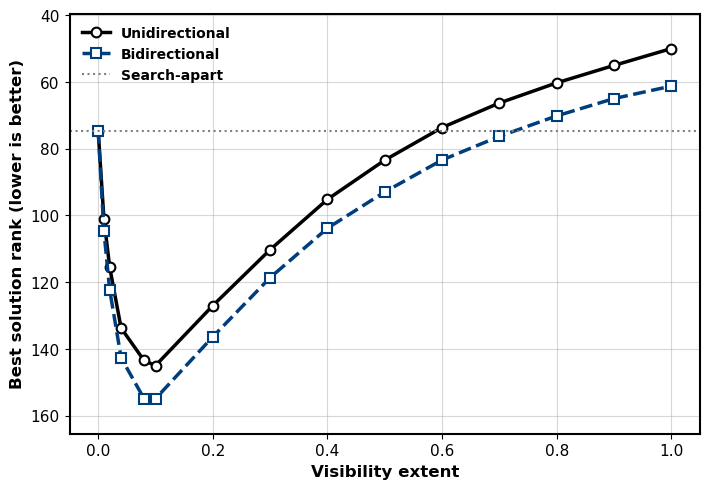

In [6]:
plot_across_extent('breakthrough_rank', 'Breakthrough_across_visibility_extent_bidirectional.png')

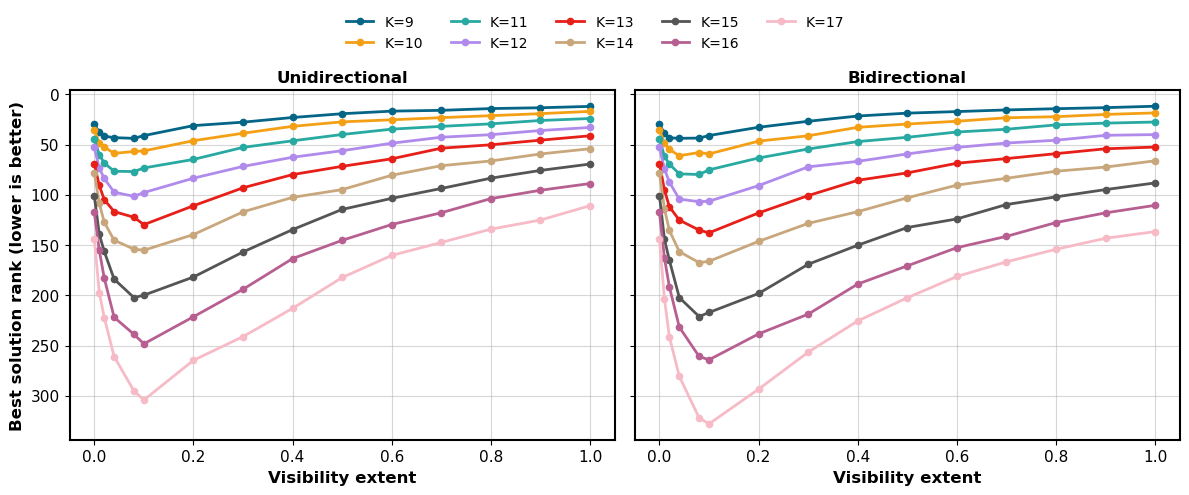

In [7]:
plot_by_K('breakthrough_rank', 'Breakthrough_by_K_across_visibility_extent_bidirectional.png')

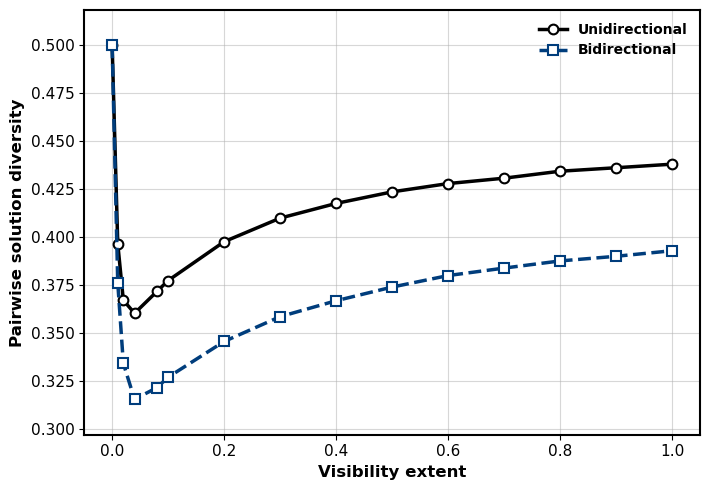

In [8]:
plot_across_extent('pairwise_diversity', 'Pairwise_diversity_across_visibility_extent_bidirectional.png')

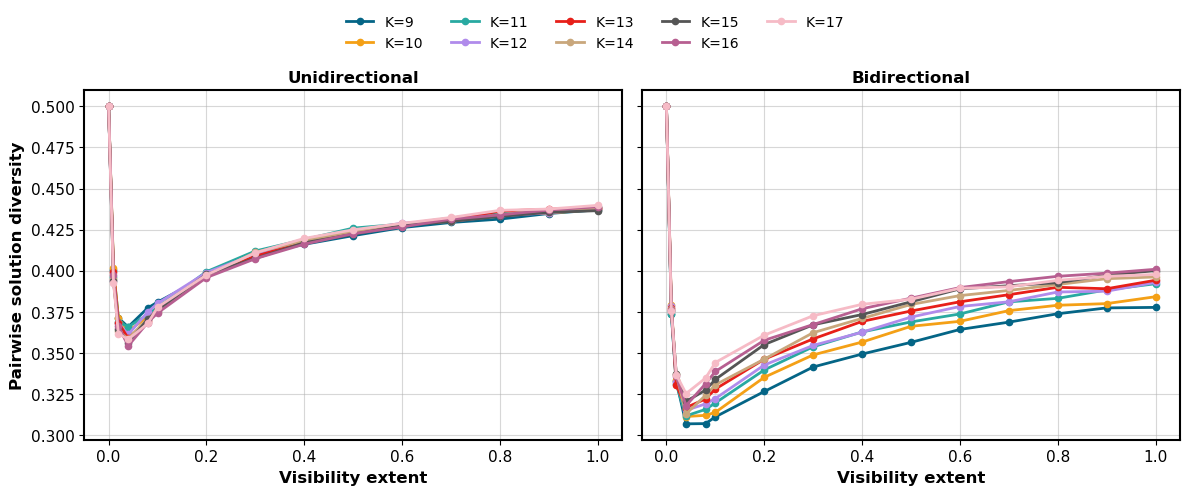

In [9]:
plot_by_K('pairwise_diversity', 'Pairwise_diversity_by_K_across_visibility_extent_bidirectional.png')

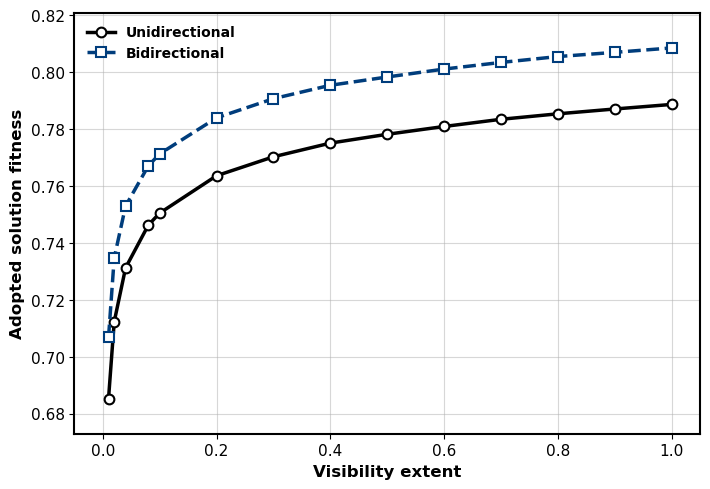

In [10]:
plot_across_extent('adopted_solution_fitness', 'Adopted_solution_quality_across_visibility_extent_bidirectional.png')

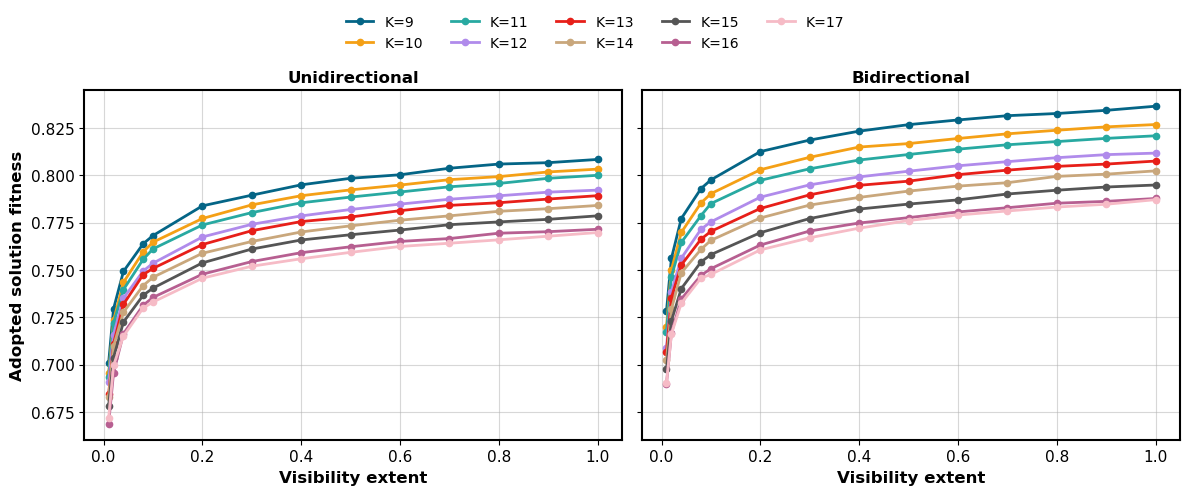

In [11]:
plot_by_K('adopted_solution_fitness', 'Adopted_solution_quality_by_K_across_visibility_extent_bidirectional.png')

## 4. Generative potential

Generative potential is calculated for sampled successful receiver adoptions using independent post-adoption search continuations. The upstream means are conditional on qualifying adoptions.

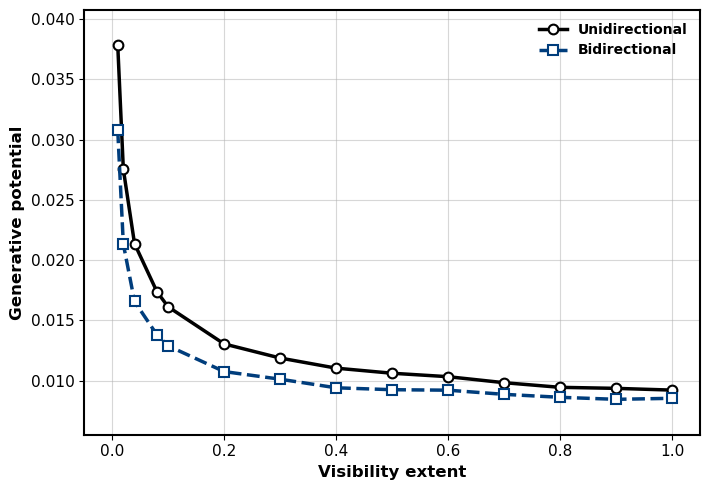

In [12]:
plot_across_extent('generative_potential', 'Generative_potential_across_visibility_extent_bidirectional.png')

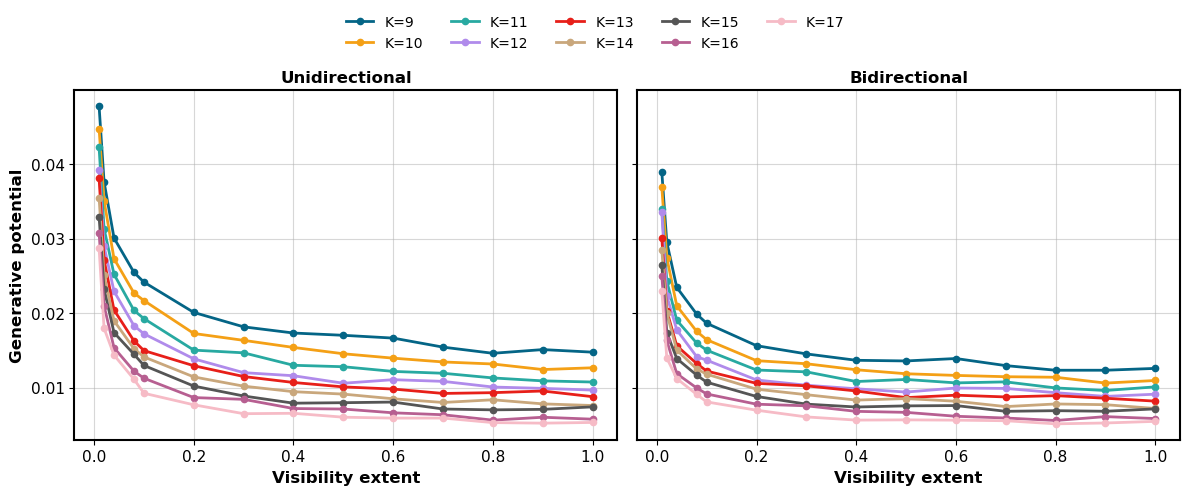

In [13]:
plot_by_K('generative_potential', 'Generative_potential_by_K_across_visibility_extent_bidirectional.png')

## 5. Additional outcomes

Breakthrough fitness is the best final receiver fitness, and unique solution count is the number of distinct final receiver configurations.

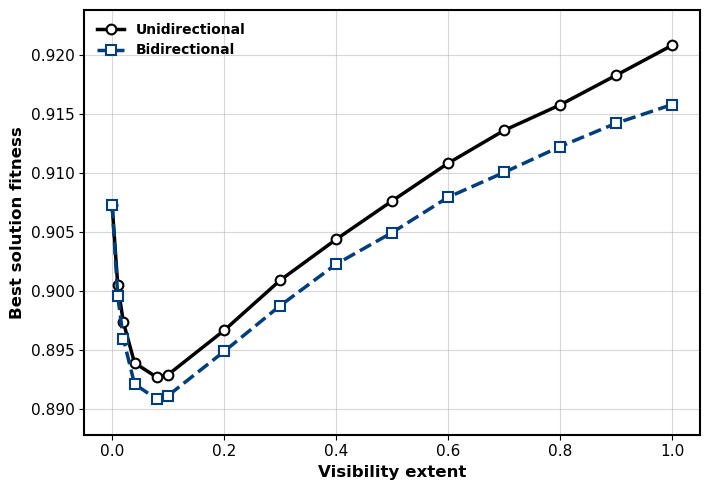

In [14]:
plot_across_extent('breakthrough_fitness', 'Best_solution_fitness_across_visibility_extent_bidirectional.png')

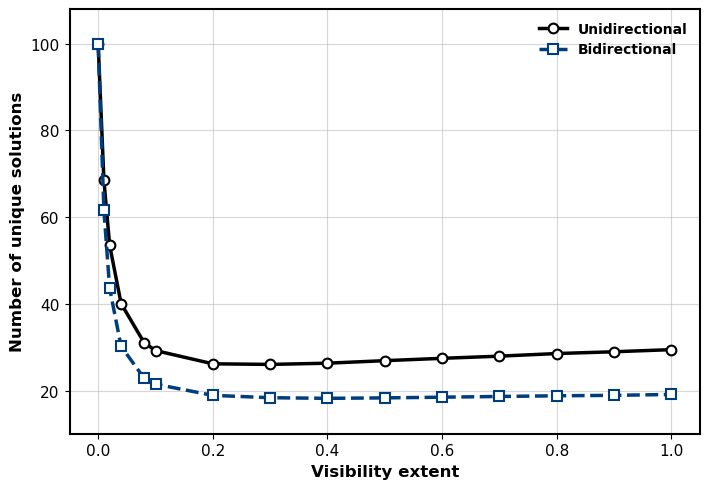

In [15]:
plot_across_extent('unique_solution_count', 'Unique_solution_count_across_visibility_extent_bidirectional.png')

## 6. Adoption-quality trajectories across search time

Set `trajectory_visibility_extent` to a sampled extent. Values are the cumulative mean objective fitness of adopted receiver solutions through each event (not event-specific adoption fitness or overall receiver fitness).

In [16]:
trajectory_visibility_extent = 1.0
if trajectory_visibility_extent not in visibility_extent_list:
    raise ValueError('trajectory_visibility_extent must appear in visibility_extent_list.')
trajectory_index = visibility_extent_list.index(trajectory_visibility_extent)
trajectory_periods = np.arange(1, expected_events + 1) * visibility_interval
trajectory_by_K = {mode: data[mode][trajectory_dv][trajectory_index] for mode in visibility_modes}
print('Trajectory extent:', trajectory_visibility_extent)
print('Visibility events:', len(trajectory_periods))

Trajectory extent: 1.0
Visibility events: 30


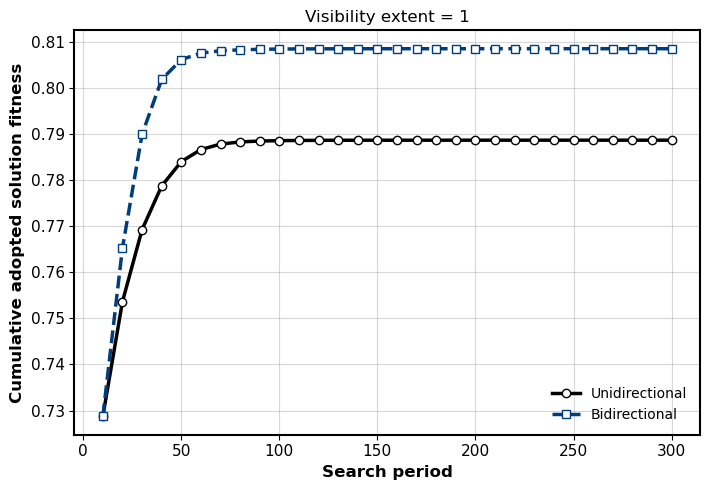

In [17]:
fig, ax = plt.subplots(figsize=(7.2, 5.0))
format_axis(ax)
for mode in visibility_modes:
    ax.plot(trajectory_periods, safe_nanmean(trajectory_by_K[mode], axis=0),
            linewidth=2.5, markersize=6, label=MODE_LABELS[mode], **MODE_STYLES[mode])
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.set_title(f'Visibility extent = {trajectory_visibility_extent:g}')
ax.legend(frameon=False)
finish_figure(fig, f'Adopted_solution_fitness_across_search_periods_extent_{trajectory_visibility_extent:g}_bidirectional.png')

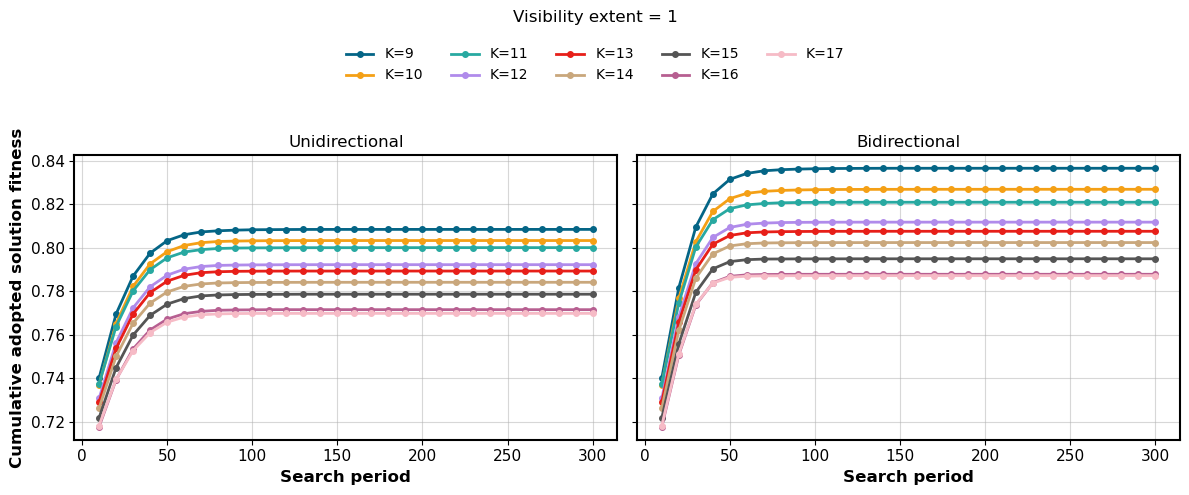

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), sharey=True)
for ax, mode in zip(axes, visibility_modes):
    format_axis(ax)
    for j, K in enumerate(K_list):
        ax.plot(trajectory_periods, trajectory_by_K[mode][j], marker='o', linewidth=2.0,
                markersize=4, color=K_colors[j % len(K_colors)], label=f'K={K}')
    ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
    ax.set_title(MODE_LABELS[mode])
axes[0].set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.suptitle(f'Visibility extent = {trajectory_visibility_extent:g}')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.93), ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.82))
fig.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_extent_{trajectory_visibility_extent:g}_bidirectional.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
plt.close(fig)

## 7. Visibility × landscape complexity

The two panels use the same color scale for each outcome. Undefined values are blank. All cells are the original saved `(extent, K)` means for the specified mode.

In [19]:
def plot_heatmap(dv):
    arrays = [data[mode][dv].T for mode in visibility_modes]
    finite = np.concatenate([a[np.isfinite(a)] for a in arrays])
    if finite.size == 0:
        print(f'Skipping {dv}: no defined values.')
        return
    lo, hi = finite.min(), finite.max()
    if lo == hi:
        hi = lo + max(abs(lo) * 1e-6, 1e-6)
    fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.0), sharey=True, constrained_layout=True)
    for ax, mode, values in zip(axes, visibility_modes, arrays):
        image = ax.imshow(np.ma.masked_invalid(values), aspect='auto', interpolation='nearest',
                          cmap='viridis_r' if dv == 'breakthrough_rank' else 'viridis',
                          origin='lower', vmin=lo, vmax=hi)
        ax.set_xticks(np.arange(len(visibility_extent_list)))
        ax.set_xticklabels([f'{v:g}' for v in visibility_extent_list], rotation=45, ha='right')
        ax.set_yticks(np.arange(len(K_list)))
        ax.set_yticklabels(K_list)
        ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
        ax.set_title(MODE_LABELS[mode], fontweight='bold')
    axes[0].set_ylabel('K', fontweight='bold', fontsize=12)
    fig.suptitle(LABELS[dv], fontweight='bold')
    fig.colorbar(image, ax=axes, label=LABELS[dv], pad=0.02)
    fig.savefig(figure_folder / f'{dv}_heatmap_across_extent_and_K_bidirectional.png', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close(fig)

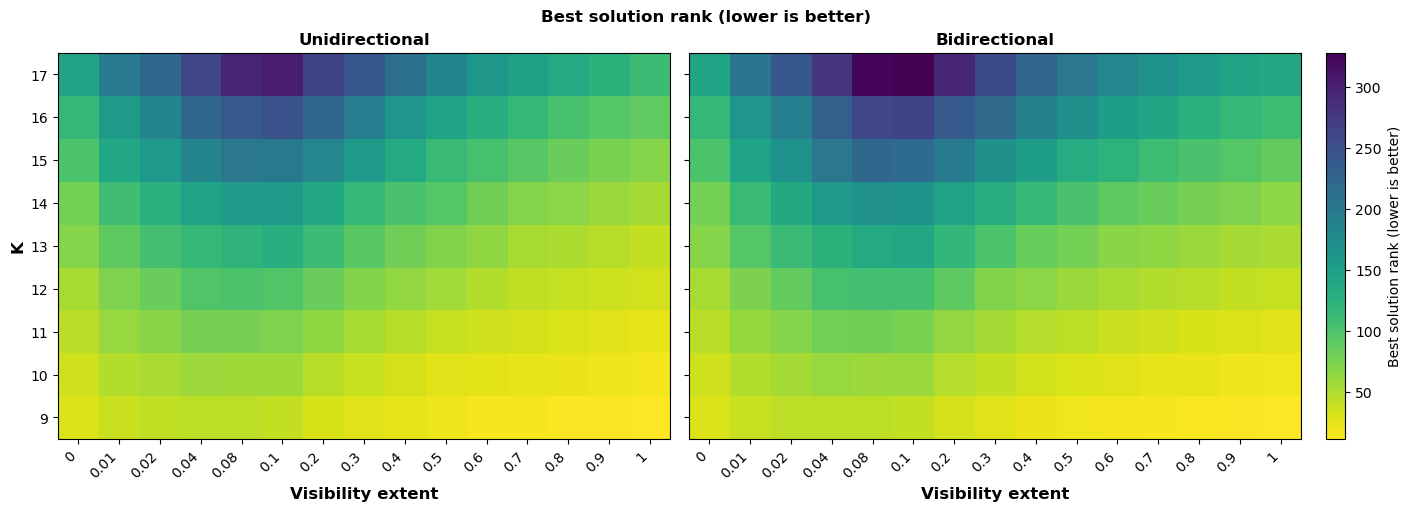

In [20]:
plot_heatmap('breakthrough_rank')

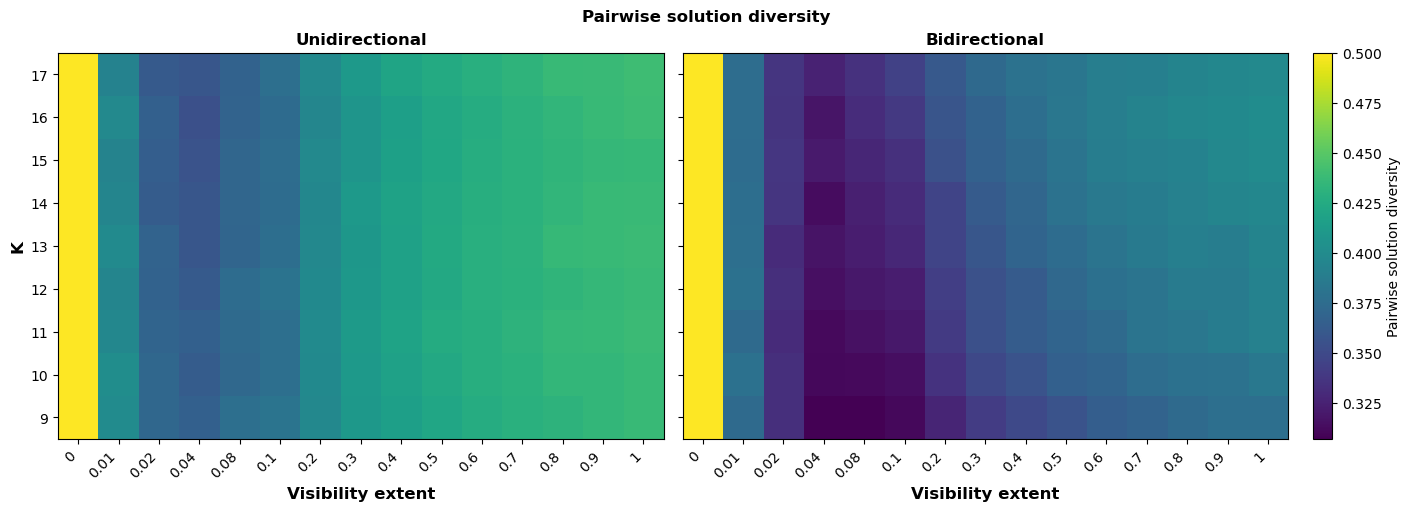

In [21]:
plot_heatmap('pairwise_diversity')

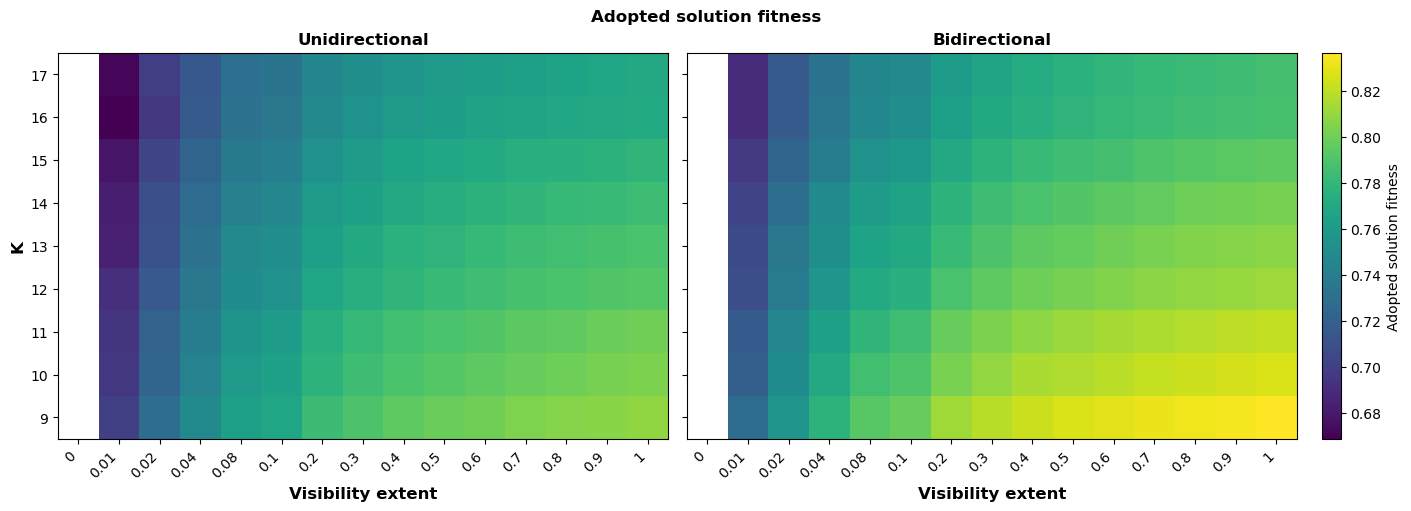

In [22]:
plot_heatmap('adopted_solution_fitness')

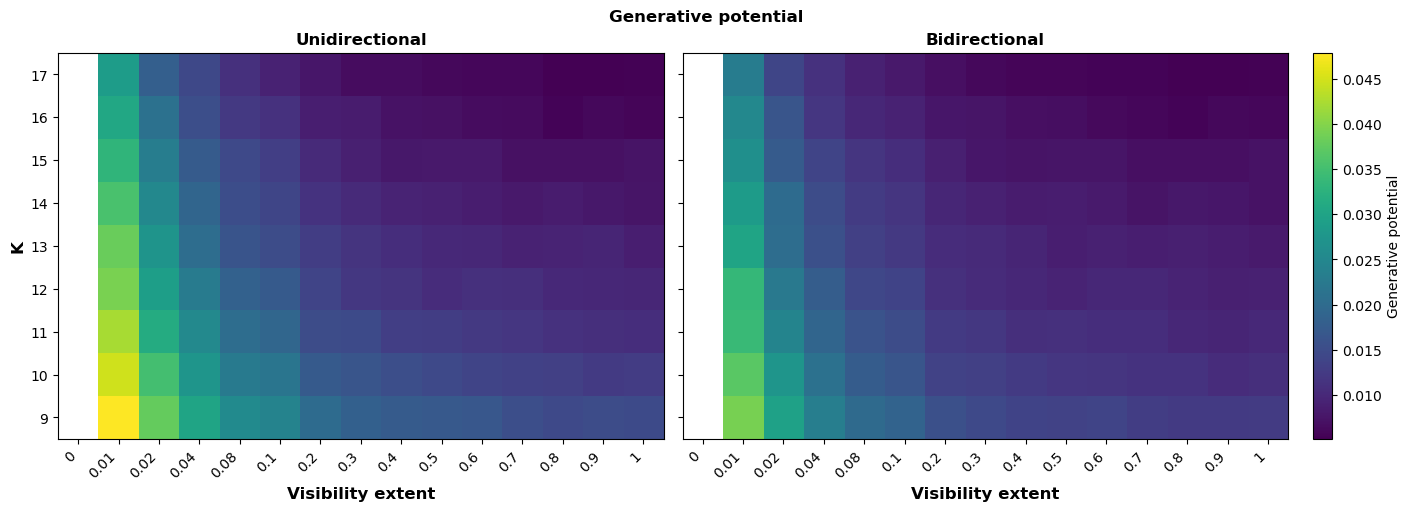

In [23]:
plot_heatmap('generative_potential')

## 8. Optional run-level paired analysis

CSV input: `visibility_extent_{extent}_interval_{interval}_bidirectional_comparison_size_{agent_num}_runs.csv`.

Pair on `(visibility_extent, K, landscape_replication, solver_reset)` (the interval is held fixed). The expected count is 18,000 paired observations per extent: 9 K values × 400 landscapes × 5 resets. Incomplete landscapes are excluded from paired inference; by default, missing CSVs do not prevent the pickle-based figures from running. CSV checks reject duplicate keys or inconsistent condition labels. For partial CSVs, only complete landscapes enter the contrasts, which remain undefined if any K stratum has fewer than two complete landscapes.

In [24]:
pair_keys = ['visibility_extent', 'K', 'landscape_replication', 'solver_reset']
raw_outcomes = scalar_dvs + ['receiver_adoption_count', 'sender_adoption_count']
required_columns = pair_keys + ['visibility_interval', 'bidirectional_visibility'] + raw_outcomes
raw_frames = []
if load_run_level:
    for extent in visibility_extent_list:
        path = result_folder / (f'visibility_extent_{extent}_interval_{visibility_interval}'
                                f'_bidirectional_comparison_size_{agent_num}_runs.csv')
        if not path.is_file():
            if strict_run_level:
                raise FileNotFoundError(path)
            print('CSV not found:', path.name)
            continue
        frame = pd.read_csv(path)
        missing_columns = set(required_columns) - set(frame.columns)
        if missing_columns:
            raise ValueError(f'{path.name}: missing columns {missing_columns}')
        frame = frame[required_columns].copy()
        for col in required_columns:
            frame[col] = pd.to_numeric(frame[col], errors='raise')
        valid = (np.isclose(frame['visibility_extent'], extent, rtol=0, atol=1e-12)
                 & frame['visibility_interval'].eq(visibility_interval)
                 & frame['K'].isin(K_list)
                 & frame['landscape_replication'].isin(range(landscape_iteration))
                 & frame['solver_reset'].isin(range(solver_reset_num))
                 & frame['bidirectional_visibility'].isin(visibility_modes))
        if not valid.all():
            raise ValueError(f'{path.name}: unexpected experiment identifiers.')
        frame['visibility_extent'] = extent
        if frame.duplicated(pair_keys + ['bidirectional_visibility']).any():
            raise ValueError(f'{path.name}: duplicate run identifiers.')
        if len(frame) != len(K_list) * landscape_iteration * solver_reset_num * 2:
            msg = f'{path.name}: incomplete rows ({len(frame)}).'
            if strict_run_level:
                raise ValueError(msg)
            warnings.warn(msg)
        raw_frames.append(frame)
raw_results = pd.concat(raw_frames, ignore_index=True) if raw_frames else pd.DataFrame(columns=required_columns)
print('Run-level rows loaded:', len(raw_results))

if not raw_results.empty:
    a = raw_results.query('bidirectional_visibility == 0').set_index(pair_keys)
    b = raw_results.query('bidirectional_visibility == 1').set_index(pair_keys)
    common = a.index.intersection(b.index)
    paired_differences = b.loc[common, raw_outcomes] - a.loc[common, raw_outcomes]
    print('Matched pairs:', len(common), '| unmatched mode rows:', len(a) + len(b) - 2 * len(common))
    if strict_run_level and len(common) != len(visibility_extent_list) * len(K_list) * landscape_iteration * solver_reset_num:
        raise ValueError('Incomplete paired run-level data.')
    zero = paired_differences.index.get_level_values('visibility_extent') == 0
    if zero.any():
        for dv in ['breakthrough_rank', 'breakthrough_fitness', 'pairwise_diversity', 'unique_solution_count',
                   'receiver_adoption_count', 'sender_adoption_count']:
            if not np.allclose(paired_differences.loc[zero, dv], 0, rtol=0, atol=1e-10):
                warnings.warn(f'Run-level zero-visibility mismatch: {dv}')
    # Reconcile CSV scalar means against the pickle values, for fully populated conditions.
    grouped = raw_results.groupby(['visibility_extent', 'K', 'bidirectional_visibility'])
    csv_means, csv_counts = grouped[scalar_dvs].mean(), grouped.size()
    gaps = []
    for i, extent in enumerate(visibility_extent_list):
        for j, K in enumerate(K_list):
            for mode in visibility_modes:
                key = (extent, K, mode)
                if csv_counts.get(key, 0) == landscape_iteration * solver_reset_num:
                    for dv in scalar_dvs:
                        x, y = csv_means.loc[key, dv], data[mode][dv][i, j]
                        if np.isfinite(x) and np.isfinite(y):
                            gaps.append(abs(x-y))
                            if not np.isclose(x, y, rtol=1e-9, atol=1e-10):
                                warnings.warn(f'CSV/pickle mismatch: {key}, {dv}')
    if gaps:
        print('Max finite CSV/pickle mean discrepancy:', max(gaps))
else:
    paired_differences = pd.DataFrame(columns=raw_outcomes)
    print('Paired analysis skipped: no run-level CSV data.')

Run-level rows loaded: 540000
Matched pairs: 270000 | unmatched mode rows: 0
Max finite CSV/pickle mean discrepancy: 2.9976021664879227e-15


### 8.1. Paired effects and approximate 95% confidence intervals

The contrast is bidirectional minus unidirectional. Negative rank differences indicate improved breakthrough discovery. For each extent and K, first average the matched differences over all five resets within each landscape, then average across independent landscape replications. Give K strata equal weight. The pointwise normal-approximation 95% interval uses the stratified standard error `sqrt(sum_k(s_k² / n_k)) / number_of_K`, where `s_k²` is the sample variance of landscape-level differences and `n_k` the number of complete landscapes in stratum K. The intervals are not simultaneous bands. No independent-reset assumption is made. Only always-defined outcomes enter these contrasts; adoption-dependent conditional means remain in the descriptive figures above.

In [25]:
paired_outcomes = ['breakthrough_rank', 'breakthrough_fitness', 'pairwise_diversity', 'unique_solution_count']
contrast_rows = []
if not paired_differences.empty:
    for dv in paired_outcomes:
        by_landscape = paired_differences[dv].groupby(level=['visibility_extent', 'K', 'landscape_replication'])
        counts = by_landscape.count()
        landscape_means = by_landscape.mean()[counts.eq(solver_reset_num)]
        for extent in visibility_extent_list:
            strata = landscape_means[landscape_means.index.get_level_values('visibility_extent') == extent].groupby(level='K').agg(['mean', 'var', 'count']).reindex(K_list)
            n_landscapes = int(strata['count'].sum())
            if strata['count'].ge(2).all():
                estimate = strata['mean'].mean()
                se = np.sqrt((strata['var'] / strata['count']).sum()) / len(K_list)
            else:
                estimate = se = np.nan
            contrast_rows.append(dict(visibility_extent=extent, outcome=dv,
                                      difference=estimate, standard_error=se,
                                      ci_low=estimate-1.96*se, ci_high=estimate+1.96*se,
                                      n_landscapes=n_landscapes))
paired_summary = pd.DataFrame(contrast_rows)
if not paired_summary.empty:
    display(paired_summary.query("outcome == 'breakthrough_rank'").round(4))

,visibility_extent,outcome,difference,standard_error,ci_low,ci_high,n_landscapes
0,0.00,breakthrough_rank,0.0000,0.0000,0.0000,0.0000,3600
1,0.01,breakthrough_rank,3.6459,0.4807,2.7037,4.5882,3600
2,0.02,breakthrough_rank,6.8022,0.7457,5.3407,8.2638,3600
3,0.04,breakthrough_rank,8.8902,1.1509,6.6345,11.1459,3600
4,0.08,breakthrough_rank,11.4435,1.4419,8.6175,14.2695,3600
5,0.10,breakthrough_rank,9.9169,1.4504,7.0741,12.7598,3600
6,0.20,breakthrough_rank,9.3438,1.3758,6.6473,12.0403,3600
7,0.30,breakthrough_rank,8.3708,1.2632,5.8949,10.8468,3600
8,0.40,breakthrough_rank,8.6403,1.1049,6.4747,10.8059,3600
9,0.50,breakthrough_rank,9.5277,0.9756,7.6155,11.4399,3600


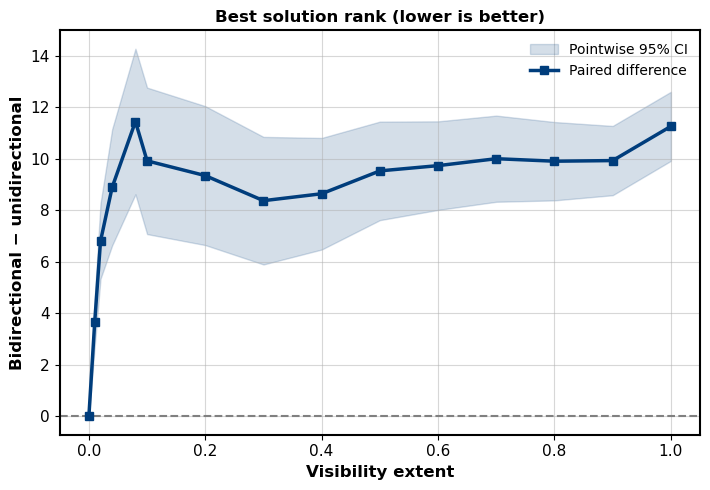

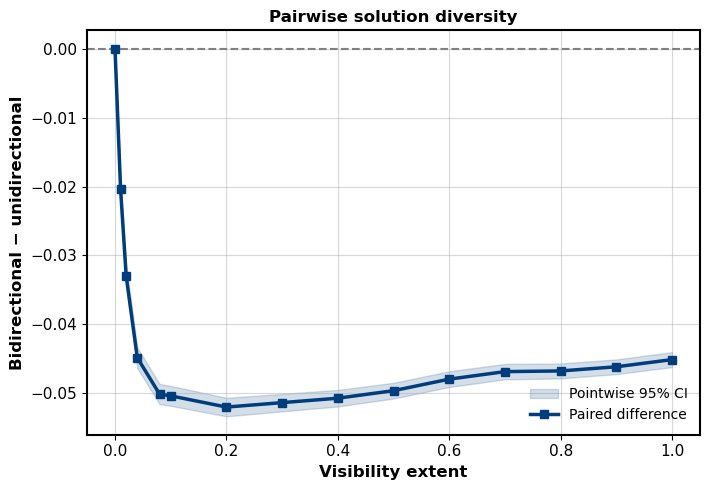

In [26]:
def plot_paired_contrast(dv):
    if paired_summary.empty:
        return
    subset = paired_summary.loc[paired_summary['outcome'].eq(dv)]
    if not subset['difference'].notna().any():
        print(f'No complete paired estimates for {dv}.')
        return
    x = subset['visibility_extent'].to_numpy(float)
    y = subset['difference'].to_numpy(float)
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    format_axis(ax)
    ax.axhline(0, color='gray', linestyle='--', linewidth=1.5)
    ax.fill_between(x, subset['ci_low'].to_numpy(float), subset['ci_high'].to_numpy(float),
                    color=nus_blue, alpha=0.17, label='Pointwise 95% CI')
    ax.plot(x, y, color=nus_blue, marker='s', linewidth=2.5, label='Paired difference')
    ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
    ax.set_ylabel('Bidirectional − unidirectional', fontweight='bold', fontsize=12)
    ax.set_title(LABELS[dv], fontweight='bold')
    ax.legend(frameon=False)
    finish_figure(fig, f'{dv}_paired_difference_across_extent.png')

plot_paired_contrast('breakthrough_rank')
plot_paired_contrast('pairwise_diversity')

### 8.2. Adoption-count diagnostics

Receiver counts are recorded in both modes; sender counts should be zero in the unidirectional mode and at zero visibility. These are mean counts per run, not rates or combined-population performance. Only matched pairs with finite counts in both modes are used, with equal weighting across available K strata.

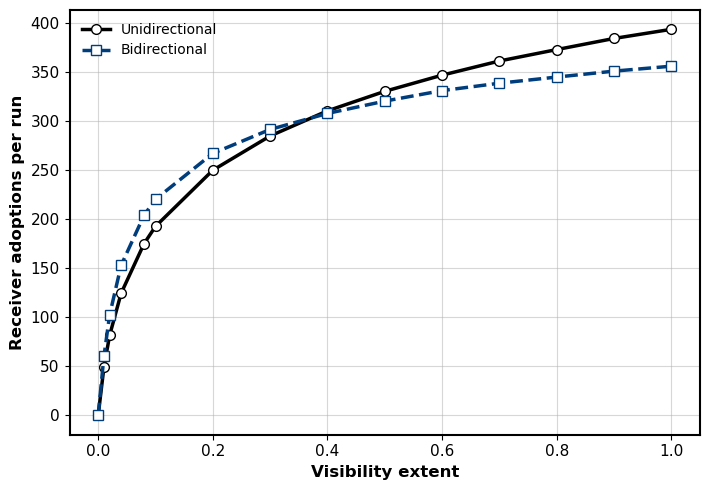

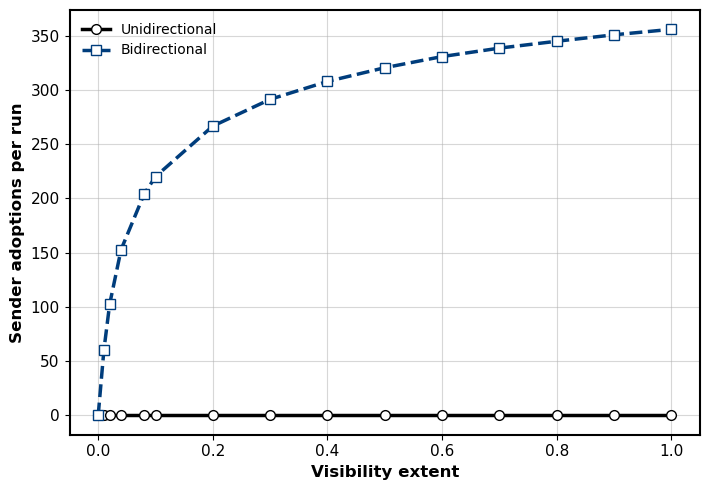

In [27]:
if not raw_results.empty and len(common):
    for dv, label in [('receiver_adoption_count', 'Receiver adoptions per run'),
                      ('sender_adoption_count', 'Sender adoptions per run')]:
        aa, bb = a.loc[common, dv], b.loc[common, dv]
        finite = np.isfinite(aa) & np.isfinite(bb)
        if dv == 'sender_adoption_count' and not np.allclose(aa[finite], 0, rtol=0, atol=0):
            warnings.warn('Unexpected sender adoptions in unidirectional mode.')
        fig, ax = plt.subplots(figsize=(7.2, 5.0))
        format_axis(ax)
        for mode, series in [(0, aa), (1, bb)]:
            means = series[finite].groupby(level=['visibility_extent', 'K']).mean().groupby(level='visibility_extent').mean()
            ax.plot(visibility_extent_list, means.reindex(visibility_extent_list),
                    label=MODE_LABELS[mode], linewidth=2.5, markersize=7, **MODE_STYLES[mode])
        ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
        ax.set_ylabel(label, fontweight='bold', fontsize=12)
        ax.legend(frameon=False)
        finish_figure(fig, f'{dv}_across_extent_bidirectional.png')